# StockVision AI – Stock Price Forecasting Using GRU

**Student:** Ritik Raj  
**Registration:** 23FE10ITE00256  
**Course:** Deep Learning · **University:** Manipal University Jaipur  
**Case Study:** 7 — Stock Price / Time-Series Forecasting

## Goal
Forecast the next trading day's Apple (AAPL) closing price from the previous 60 observations. This notebook uses the local historical file copied byte-for-byte from `D:/Stocks/aapl.us.txt`, a Kaggle-style OHLCV archive (1984-09-07 through 2017-11-10). If the dataset is not at `dataset/AAPL.csv`, the loader prompts for a file upload in Google Colab.

## Method
We use Close as the single feature and target, split target dates chronologically into 70% training, 15% validation, and 15% test, fit MinMaxScaler on training rows only, and compare the GRU with prior-close persistence. Inputs never include their target date. Training sequences are not shuffled. Validation controls early stopping; test data is held out for the final comparison.

## GRU
Input `(60, 1)` → GRU(64, sequences) → Dropout(0.2) → GRU(32) → Dropout(0.2) → Dense(16, ReLU) → Dense(1). Adam (0.001), MSE loss, MAE metric, batch size 32, maximum 50 epochs, patience 8, seed 42.


In [1]:
"""StockVision AI: chronological AAPL next-day close forecasting with GRU."""
from pathlib import Path
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

ROOT = Path.cwd()
DATA_PATH = ROOT / "dataset" / "AAPL.csv"
RESULTS = ROOT / "outputs"
LOOKBACK, SEED = 60, 42
FEATURES = ["Close"]




## 1. Load and inspect the historical AAPL data

The loader parses dates, checks numeric Close values, sorts dates, removes invalid rows and duplicate dates, and asserts finite observations. The source archive also has Open, High, Low, Volume, and OpenInt; this experiment intentionally uses only Close to match the assigned input shape.

In [2]:
def load_data(path=DATA_PATH):
    path = Path(path)
    if not path.exists():
        try:
            from google.colab import files
            print("Upload the AAPL historical dataset CSV/TXT file.")
            uploaded = files.upload()
            if not uploaded:
                raise FileNotFoundError("No file uploaded. Put AAPL.csv in dataset/ and retry.")
            name, content = next(iter(uploaded.items()))
            path.parent.mkdir(parents=True, exist_ok=True)
            path.write_bytes(content)
        except ImportError as exc:
            raise FileNotFoundError(f"AAPL dataset not found at {path}. Copy AAPL.csv there or, in Colab, upload the dataset when prompted.") from exc
    df = pd.read_csv(path)
    df.columns = [str(c).strip().title() for c in df.columns]
    required = ["Date", *FEATURES]
    missing = set(required) - set(df.columns)
    if missing:
        raise ValueError(f"CSV missing required columns: {sorted(missing)}")
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
    for c in FEATURES:
        df[c] = pd.to_numeric(df[c].astype(str).str.replace(",", "", regex=False), errors="coerce")
    df = df.dropna(subset=required).sort_values("Date").drop_duplicates("Date", keep="last").reset_index(drop=True)
    if len(df) < 100:
        raise ValueError("Need at least 100 valid daily observations for chronological splits and a 60-day lookback.")
    if not np.isfinite(df[FEATURES].to_numpy()).all():
        raise ValueError("Non-finite feature values remain after cleaning.")
    assert df.Date.is_monotonic_increasing and not df.Date.duplicated().any()
    return df



df = load_data()
print("Rows and columns:", df.shape)
print("Date range:", df.Date.min().date(), "to", df.Date.max().date())
print("Data types:\n", df.dtypes)
print("Missing values after cleaning:\n", df.isna().sum())
print("Duplicate dates:", df.Date.duplicated().sum())
display(df.head(), df.describe(include="all"))


Rows and columns: (8364, 7)
Date range: 1984-09-07 to 2017-11-10
Data types:
 Date       datetime64[us]
Open              float64
High              float64
Low               float64
Close             float64
Volume              int64
Openint             int64
dtype: object
Missing values after cleaning:
 Date       0
Open       0
High       0
Low        0
Close      0
Volume     0
Openint    0
dtype: int64
Duplicate dates: 0


,Date,Open,High,Low,Close,Volume,Openint
0,1984-09-07,0.42388,0.42902,0.41874,0.42388,23220030,0
1,1984-09-10,0.42388,0.42516,0.41366,0.42134,18022532,0
2,1984-09-11,0.42516,0.43668,0.42516,0.42902,42498199,0
3,1984-09-12,0.42902,0.43157,0.41618,0.41618,37125801,0
4,1984-09-13,0.43927,0.44052,0.43927,0.43927,57822062,0


,Date,Open,High,Low,Close,Volume,Openint
count,8364,8364.000000,8364.000000,8364.000000,8364.000000,8.364000e+03,8364.0
mean,2001-04-04 07:55:00.430416,22.284350,22.495867,22.054244,22.281018,1.066416e+08,0.0
min,1984-09-07 00:00:00,0.233050,0.235640,0.230510,0.230510,0.000000e+00,0.0
25%,1992-12-13 06:00:00,1.137100,1.164200,1.112800,1.137100,4.384365e+07,0.0
50%,2001-03-27 12:00:00,1.632800,1.663400,1.600600,1.628250,7.481383e+07,0.0
75%,2009-07-24 18:00:00,23.739000,23.930500,23.335750,23.694500,1.320534e+08,0.0
max,2017-11-10 00:00:00,175.110000,175.610000,174.270000,175.610000,2.069770e+09,0.0
std,NaN,37.763402,38.057733,37.447432,37.764469,9.935187e+07,0.0


## 2. Build chronological sequences

The scaler is fitted using the first 70% of rows. Targets belong to non-overlapping chronological partitions. Validation/test windows are allowed historical context from earlier rows, but each target date remains in its own partition.

In [3]:
def prepare(df):
    n = len(df)
    train_end, val_end = int(n * .70), int(n * .85)
    assert 0 < LOOKBACK < train_end < val_end < n
    # Fit all feature scaling parameters on training rows only.
    scaler = MinMaxScaler().fit(df.loc[:train_end-1, FEATURES])
    scaled = scaler.transform(df[FEATURES]).astype(np.float32)
    close_idx = FEATURES.index("Close")
    # A target at row t uses rows t-60...t-1, never row t or later.
    X, y, dates, previous_close = [], [], [], []
    for t in range(LOOKBACK, n):
        X.append(scaled[t-LOOKBACK:t])
        y.append(scaled[t, close_idx])
        dates.append(df.Date.iloc[t])
        previous_close.append(df.Close.iloc[t-1])
    X, y, dates = np.asarray(X), np.asarray(y, dtype=float), pd.DatetimeIndex(dates)
    target_rows = np.arange(LOOKBACK, n)
    train = target_rows < train_end
    valid = (target_rows >= train_end) & (target_rows < val_end)
    test = target_rows >= val_end
    assert train.any() and valid.any() and test.any()
    assert dates[train].max() < dates[valid].min() < dates[test].min()
    assert not (set(dates[train]) & set(dates[valid]) or set(dates[valid]) & set(dates[test]))
    return (X[train], y[train], X[valid], y[valid], X[test], y[test], dates[test],
            np.asarray(previous_close)[test], scaler, close_idx, (train_end, val_end))



prepared = prepare(df)
(X_train, y_train, X_val, y_val, X_test, y_test, test_dates, persistence, scaler, close_idx, boundaries) = prepared
print("Row split boundaries:", boundaries)
print("Sequence shapes:", X_train.shape, X_val.shape, X_test.shape)
print("Target shapes:", y_train.shape, y_val.shape, y_test.shape)
assert X_train.shape[1:] == (60, 1) and X_val.shape[1:] == (60, 1) and X_test.shape[1:] == (60, 1)


Row split boundaries: (5854, 7109)
Sequence shapes: (5794, 60, 1) (1255, 60, 1) (1255, 60, 1)
Target shapes: (5794,) (1255,) (1255,)


## 3. Build, train, and evaluate the GRU

The next cell defines the prescribed architecture, prints its model summary, trains with validation-based early stopping and `shuffle=False`, inverse-transforms predictions, evaluates test metrics, compares persistence on identical dates, and writes the model and graphs to `models/` and `outputs/`.

In [4]:
def main(df=None, prepared=None):
    random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
    RESULTS.mkdir(exist_ok=True)
    if df is None:
        df = load_data()
    if prepared is None:
        prepared = prepare(df)
    (ROOT/"models").mkdir(exist_ok=True)
    (Xtr, ytr, Xv, yv, Xte, yte, test_dates, persistence, scaler,
     close_idx, boundaries) = prepared
    print(f"Rows: {len(df)} | train/validation/test target rows: {boundaries[0]}, {boundaries[1]-boundaries[0]}, {len(df)-boundaries[1]}")
    print(f"Sequences: {Xtr.shape}, {Xv.shape}, {Xte.shape}; features={FEATURES}; target=next trading day's Close")
    fig, ax = plt.subplots(figsize=(12, 4)); ax.plot(df.Date, df.Close); ax.set(title="AAPL historical daily closing price", xlabel="Date", ylabel="USD"); fig.tight_layout(); fig.savefig(RESULTS/"historical_prices.png", dpi=160); plt.close(fig)
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(LOOKBACK, len(FEATURES))),
        tf.keras.layers.GRU(64, return_sequences=True), tf.keras.layers.Dropout(.2),
        tf.keras.layers.GRU(32), tf.keras.layers.Dropout(.2),
        tf.keras.layers.Dense(16, activation="relu"), tf.keras.layers.Dense(1)
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=.001), loss="mse", metrics=["mae"])
    model.summary()
    try:
        tf.keras.utils.plot_model(model, to_file=str(RESULTS/"architecture.png"), show_shapes=True, show_layer_names=True)
    except Exception as exc:
        print(f"Keras plot_model unavailable ({exc}); writing Matplotlib diagram.")
        fig, ax = plt.subplots(figsize=(9, 2.5)); ax.axis("off")
        labels=["Input\n(60, 1)","GRU 64\nsequences", "Dropout\n0.2", "GRU 32", "Dropout\n0.2", "Dense 16\nReLU", "Dense 1\nlinear"]
        for i, label in enumerate(labels):
            x=.04+i*.16; ax.text(x,.5,label,ha="center",va="center",bbox=dict(boxstyle="round",fc="#e8f1fb"))
            if i<len(labels)-1: ax.annotate("",(x+.12,.5),(x+.05,.5),arrowprops=dict(arrowstyle="->"))
        fig.savefig(RESULTS/"architecture.png",dpi=160,bbox_inches="tight"); plt.close(fig)
    history = model.fit(Xtr,ytr,validation_data=(Xv,yv),epochs=50,batch_size=32,shuffle=False,
        callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss",patience=8,restore_best_weights=True)],verbose=2)
    train_eval = model.evaluate(Xtr, ytr, verbose=0, return_dict=True)
    val_eval = model.evaluate(Xv, yv, verbose=0, return_dict=True)
    pred = model.predict(Xte,verbose=0).ravel()
    # Invert the training-fitted Close scaling before price metrics.
    pred = (pred - scaler.min_[close_idx]) / scaler.scale_[close_idx]
    actual = (yte - scaler.min_[close_idx]) / scaler.scale_[close_idx]
    def metrics(a,p):
        return {"MAE":float(mean_absolute_error(a,p)),"RMSE":float(np.sqrt(mean_squared_error(a,p))),
                "MSE":float(mean_squared_error(a,p)),"MAPE_percent":float(mean_absolute_percentage_error(a,p)*100)}
    gru, naive = metrics(actual,pred), metrics(actual,persistence)
    comparison=pd.DataFrame([{"Model":"Naive persistence",**naive},{"Model":"GRU",**gru}])
    comparison.to_csv(RESULTS/"model_comparison.csv",index=False)
    (RESULTS/"metrics.json").write_text(json.dumps({"ticker":"AAPL","source_file":"dataset/AAPL.csv (copied byte-for-byte from D:/Stocks/aapl.us.txt)","observations":len(df),"data_start":str(df.Date.min().date()),"data_end":str(df.Date.max().date()),"test_start":str(test_dates.min().date()),"test_end":str(test_dates.max().date()),"epochs_run":len(history.history["loss"]),"training_mae_scaled":float(train_eval["mae"]),"validation_mae_scaled":float(val_eval["mae"]),"training_mae_usd":float(train_eval["mae"]/scaler.scale_[close_idx]),"validation_mae_usd":float(val_eval["mae"]/scaler.scale_[close_idx]),"gru":gru,"naive_persistence":naive},indent=2))
    pd.DataFrame({"Date":test_dates,"Actual":actual,"GRU_Predicted":pred,"Naive_Predicted":persistence,"Residual":actual-pred}).to_csv(RESULTS/"test_predictions.csv",index=False)
    fig,ax=plt.subplots(figsize=(12,5)); ax.plot(history.history["loss"],label="Training loss"); ax.plot(history.history["val_loss"],label="Validation loss"); ax.set(xlabel="Epoch",ylabel="MSE (scaled close²)",title="Training and validation loss"); ax.legend(); fig.tight_layout(); fig.savefig(RESULTS/"training_validation_loss.png",dpi=160); plt.close(fig)
    fig,ax=plt.subplots(figsize=(12,5)); ax.plot(history.history["mae"],label="Training MAE"); ax.plot(history.history["val_mae"],label="Validation MAE"); ax.set(xlabel="Epoch",ylabel="MAE (scaled close)",title="Training and validation MAE"); ax.legend(); fig.tight_layout(); fig.savefig(RESULTS/"training_validation_mae.png",dpi=160); plt.close(fig)
    fig,ax=plt.subplots(figsize=(12,5)); ax.plot(test_dates,actual,label="Actual"); ax.plot(test_dates,pred,label="GRU"); ax.plot(test_dates,persistence,label="Naive",alpha=.7); ax.set(xlabel="Date",ylabel="Close (USD)",title="Held-out test predictions"); ax.legend(); fig.tight_layout(); fig.savefig(RESULTS/"actual_vs_predicted.png",dpi=160); plt.close(fig)
    fig,axs=plt.subplots(1,2,figsize=(12,4)); axs[0].plot(test_dates,actual-pred); axs[0].axhline(0,color="black",lw=1); axs[0].set(title="Test residuals",xlabel="Date",ylabel="Actual - predicted (USD)"); axs[1].hist(actual-pred,bins=30); axs[1].set(title="Residual distribution",xlabel="Residual (USD)",ylabel="Count"); fig.tight_layout(); fig.savefig(RESULTS/"residuals.png",dpi=160); plt.close(fig)
    model.save(ROOT/"models"/"stockvision_gru.keras")
    print(comparison.to_string(index=False)); print("Test dates align to target rows:",test_dates.min().date(),"through",test_dates.max().date())


main(df, prepared)


Rows: 8364 | train/validation/test target rows: 5854, 1255, 1255
Sequences: (5794, 60, 1), (1255, 60, 1), (1255, 60, 1); features=['Close']; target=next trading day's Close


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 60, 64)         │        12,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 32)             │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,817 (89.13 KB)

 Trainable params: 22,817 (89.13 KB)

 Non-trainable params: 0 (0.00 B)

... (35 outputs left out)

182/182 - 5s - 26ms/step - loss: 5.4580e-04 - mae: 0.0163 - val_loss: 0.2318 - val_mae: 0.2874


Epoch 19/50


182/182 - 5s - 26ms/step - loss: 7.1820e-04 - mae: 0.0191 - val_loss: 0.2547 - val_mae: 0.3103


            Model       MAE      RMSE         MSE  MAPE_percent
Naive persistence  1.041674  1.484510    2.203769      1.081329
              GRU 45.562378 52.162034 2720.877789     41.728971
Test dates align to target rows: 2012-11-19 through 2017-11-10


## 4. Results and saved artifacts

The run reports MAE, RMSE, MSE, and MAPE for the GRU and naive persistence baseline in USD / percent, on the same test dates. Training and validation MAE curves are reported in scaled units and saved for review. The result files below are generated from actual model execution.


{
  "ticker": "AAPL",
  "source_file": "dataset/AAPL.csv (copied byte-for-byte from D:/Stocks/aapl.us.txt)",
  "observations": 8364,
  "data_start": "1984-09-07",
  "data_end": "2017-11-10",
  "test_start": "2012-11-19",
  "test_end": "2017-11-10",
  "epochs_run": 19,
  "training_mae_scaled": 0.03684505447745323,
  "validation_mae_scaled": 0.23989737033843994,
  "training_mae_usd": 0.8964213844586537,
  "validation_mae_usd": 5.836580672675371,
  "gru": {
    "MAE": 45.562378062075574,
    "RMSE": 52.16203397750241,
    "MSE": 2720.877788670116,
    "MAPE_percent": 41.72897109527804
  },
  "naive_persistence": {
    "MAE": 1.041674043511053,
    "RMSE": 1.4845097117473047,
    "MSE": 2.2037690842720656,
    "MAPE_percent": 1.0813285803684738
  }
}


,Model,MAE,RMSE,MSE,MAPE_percent
0,Naive persistence,1.041674,1.484510,2.203769,1.081329
1,GRU,45.562378,52.162034,2720.877789,41.728971


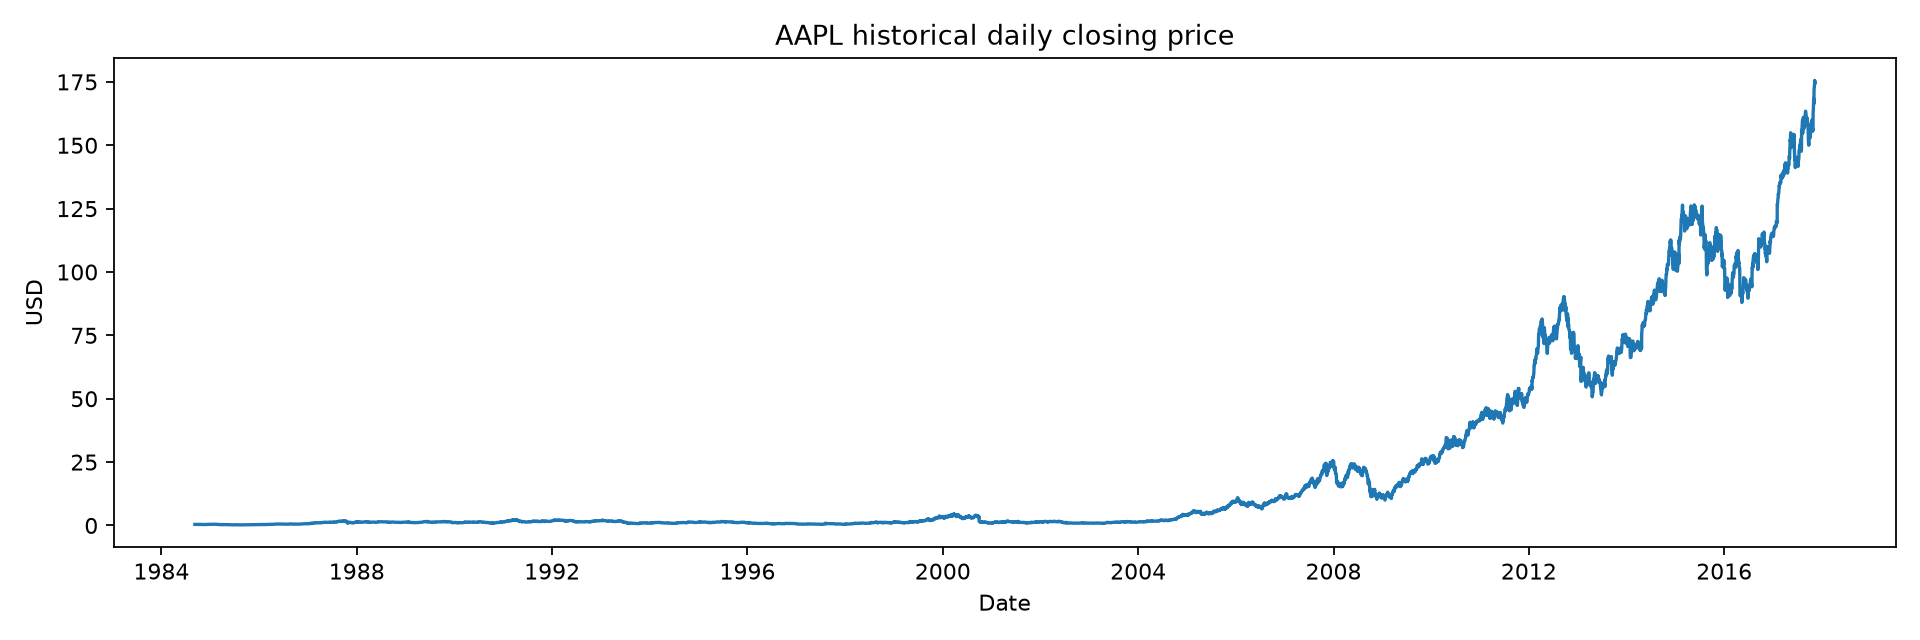

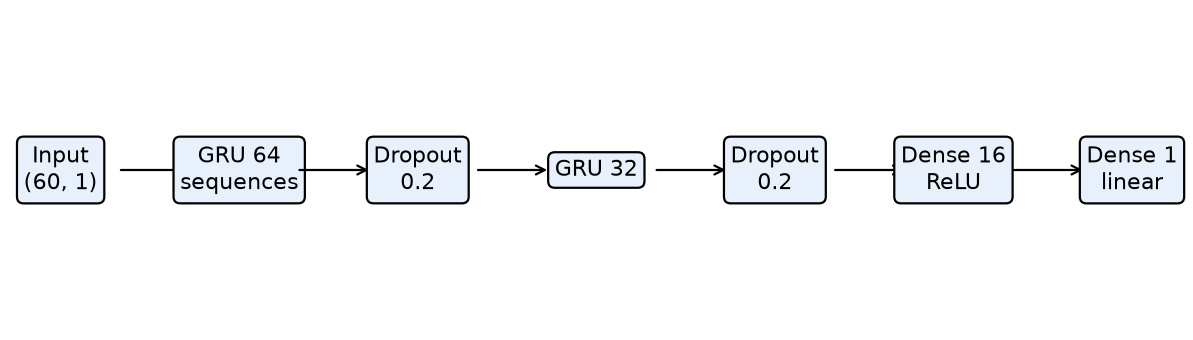

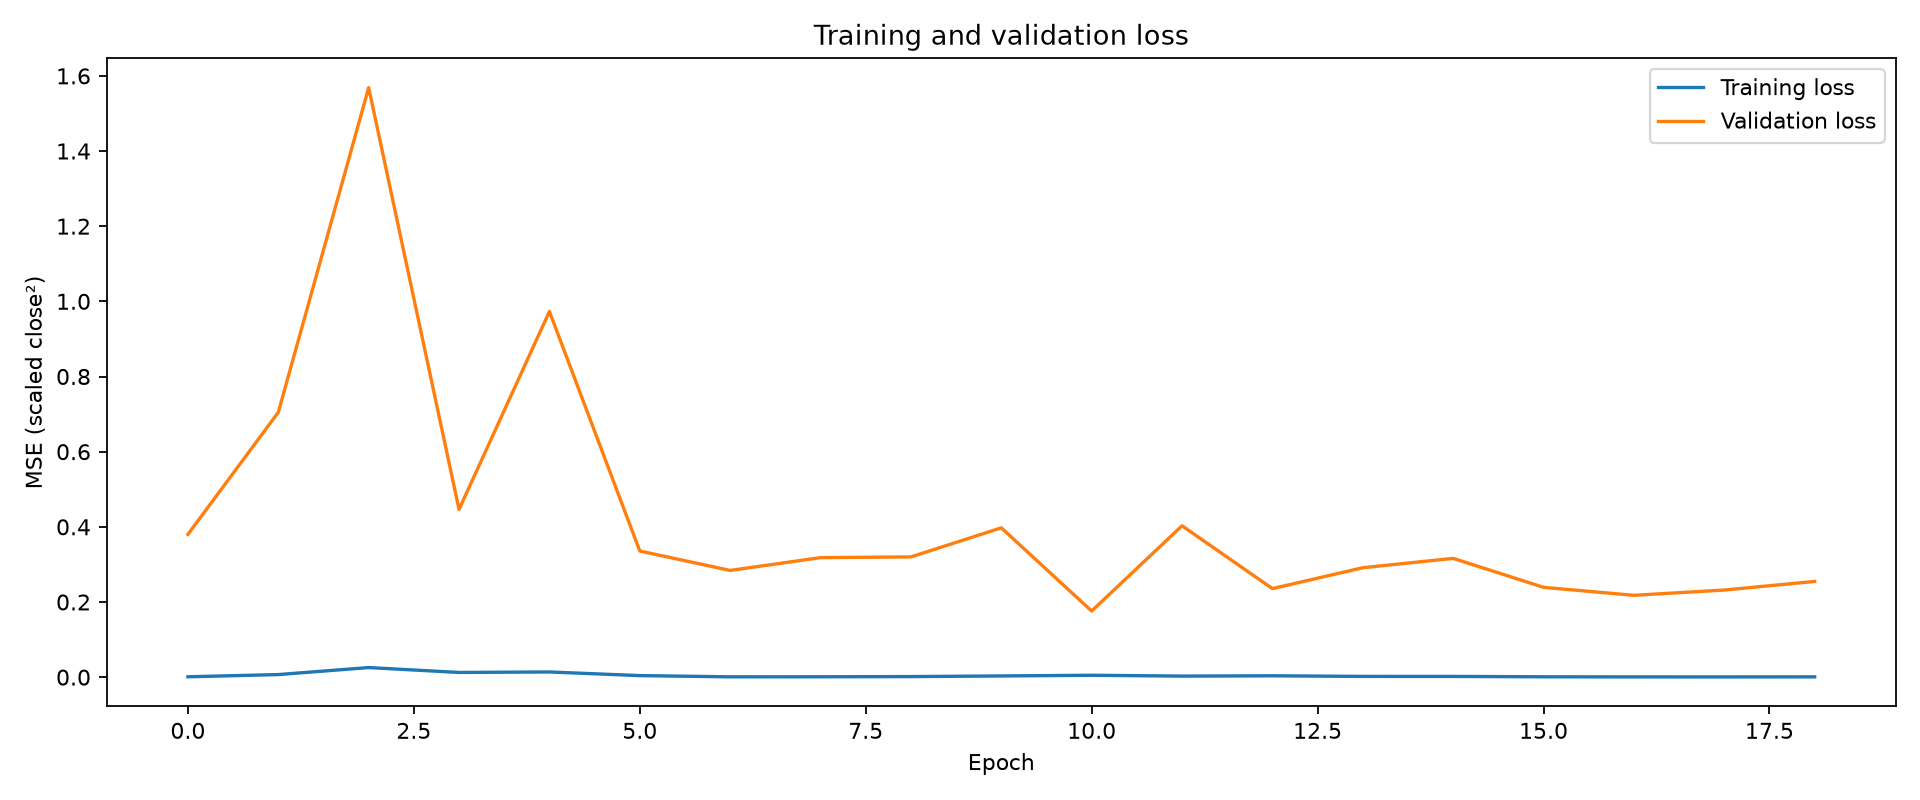

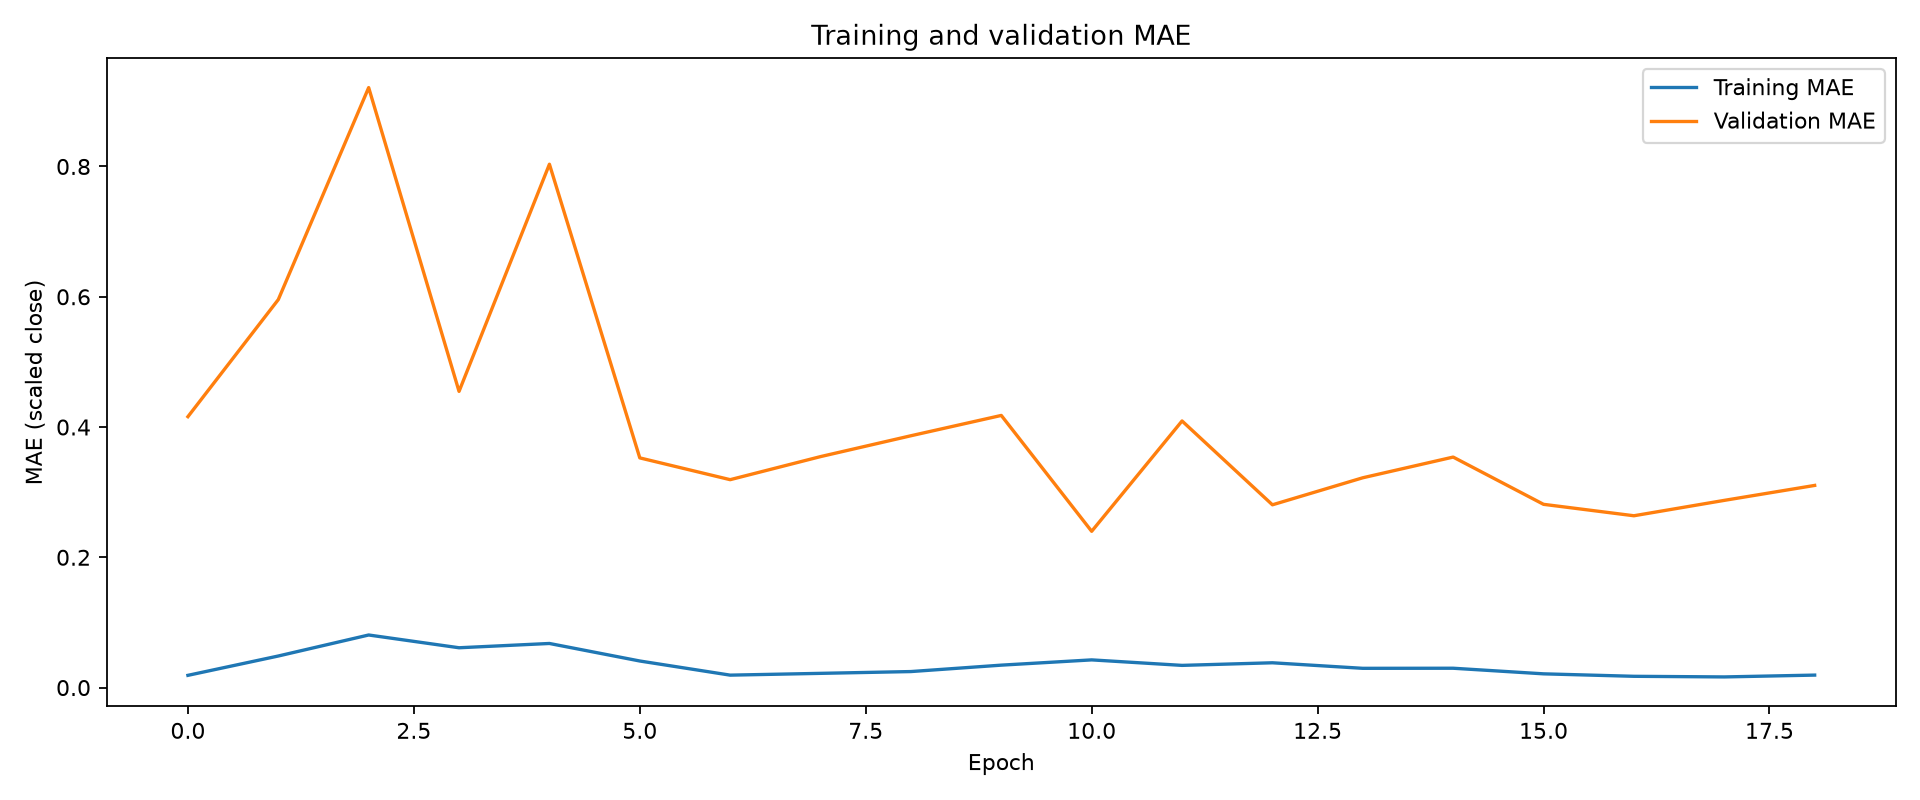

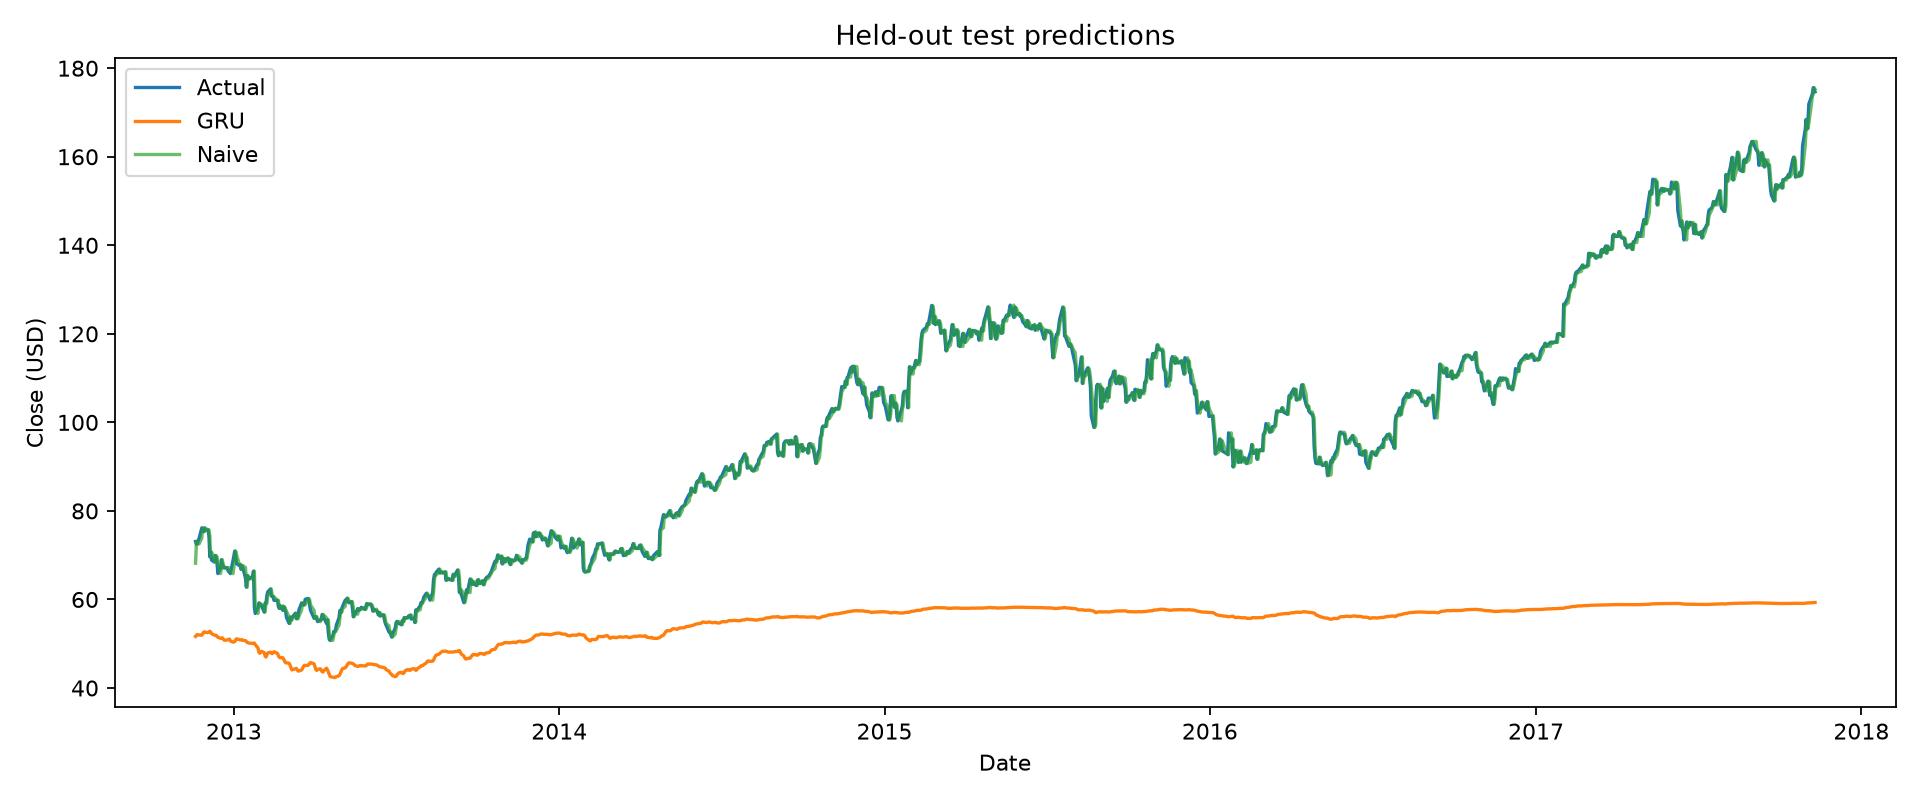

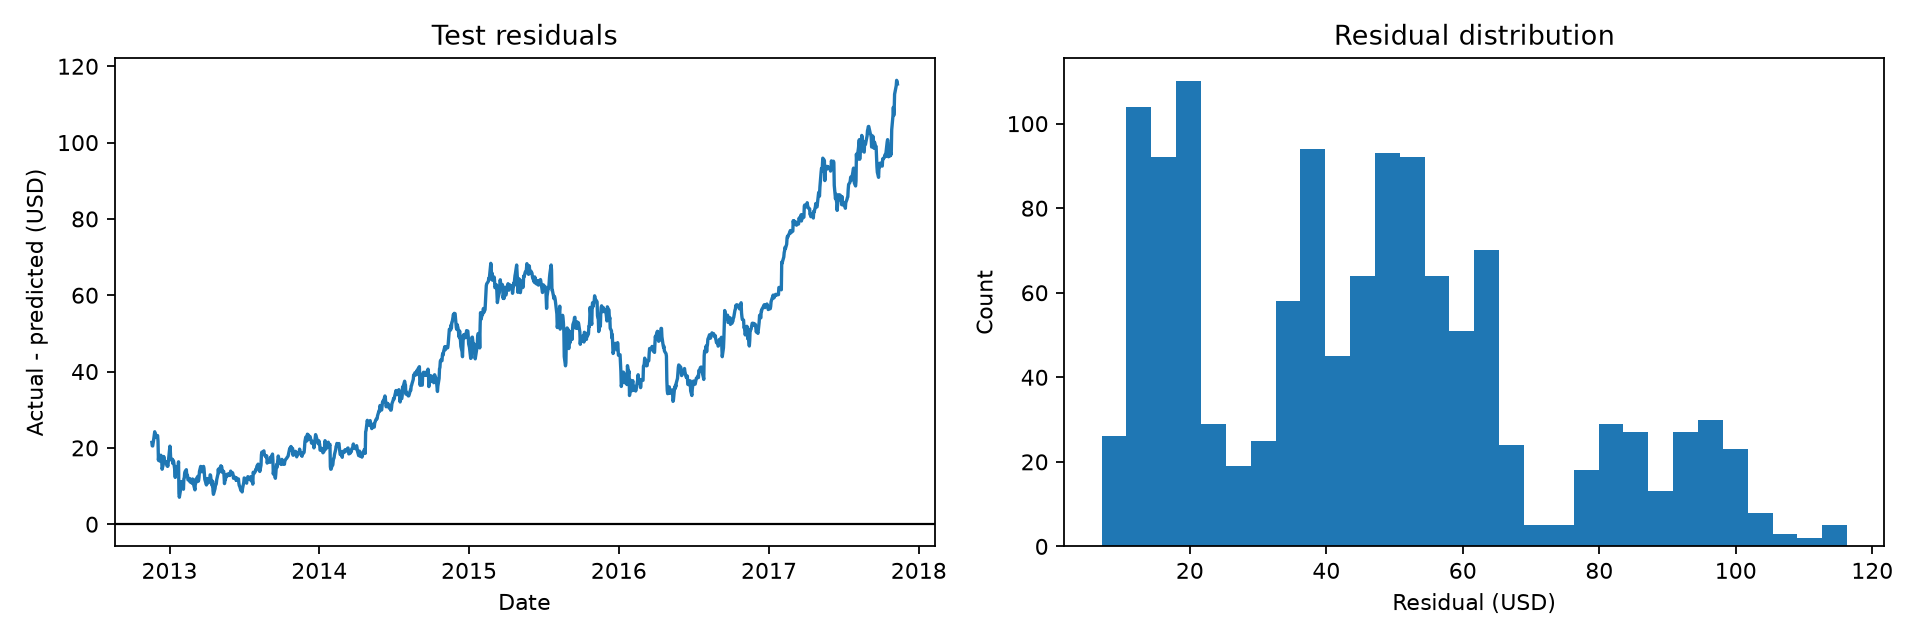

In [5]:
from IPython.display import display, Image
import pandas as pd, json
print(json.dumps(json.loads((RESULTS/"metrics.json").read_text()), indent=2))
display(pd.read_csv(RESULTS/"model_comparison.csv"))
for image_name in ["historical_prices.png", "architecture.png", "training_validation_loss.png", "training_validation_mae.png", "actual_vs_predicted.png", "residuals.png"]:
    display(Image(filename=str(RESULTS/image_name)))


## Interpretation and limitations

The measured persistence baseline strongly outperforms this GRU on the held-out period. The chronological split places training through 2007 and testing in 2012–2017, when AAPL price levels are far outside the training-only MinMax range. The model does not extrapolate this price-scale shift reliably. That is an important finding, not a reason to hide or tune on the test set. A follow-up study could forecast returns or use rolling-origin evaluation, but this submission keeps the requested next-close target and reports the baseline honestly.

Historical prices alone omit news, fundamentals, market shocks, transaction costs, and regime changes. Forecast errors do not establish trading profitability. Dataset provenance, original project attribution, and additional output details are documented in `PROJECT_REPORT.md` and `README.md`.
